# 최종 비교 — Lab 기반 모델 vs 문헌을 반영한 최적 모델

- **Lab 기반 모델:** Lab 1~6을 따라 만든 '데이터 정리 + RF(잎 176명)'. 층화 10-fold AUC 0.856
- **최적 모델:** 보충 실험 1(문헌 방법)에서 효과가 확인된 것만 모은다.
  새 변수 + 그래디언트 부스팅이 기준보다 10조각 중 9조각에서 높았고(+0.0016), Balanced RF(잎 20)는 8조각에서 높았다(+0.0005).
  쌓기(-0.0031)와 GAN 오버샘플링(보충 실험 2)은 낮아져서 넣지 않는다.

정직한 비교를 위해 **중첩 교차검증**을 쓴다. 바깥 층화 10-fold(지금까지와 같은 조각)로 성능을 재고,
설정 찾기(Random Search)는 각 조각의 학습 데이터 안에서 3-fold로만 한다. 시험 조각은 설정을 고를 때 한 번도 쓰지 않는다.

비교 기준: ① AUC ② 학습·예측 시간과 파일 크기 ③ 비용 기준 판정값에서의 손실 ④ 설명 가능성

In [1]:
import os, time, sys
import numpy, joblib
from pandas import read_csv, DataFrame
from matplotlib import pyplot, font_manager
import glob
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance

for p in glob.glob(os.path.expandvars(r'%LOCALAPPDATA%\Microsoft\Windows\Fonts\Pretendard-*.ttf')):
    font_manager.fontManager.addfont(p)
pyplot.rcParams['font.family'] = 'Pretendard'
pyplot.rcParams['axes.unicode_minus'] = False
BLUE, RED, GRAY, VIOLET, INK = '#3182F6', '#F04452', '#B0B8C1', '#7C5CFF', '#191F28'

SMOKE = os.environ.get('SMOKE') == '1'
seed = 7
names = ['target', 'revol', 'age', 'late30', 'debt', 'income', 'depend', 'defaulted', 'loans']
features = names[1:]
dataframe = read_csv('../data/givemesomecredit.csv', names=names, header=0)
X = dataframe.values[:, 1:9].astype(float)
Y = dataframe.values[:, 0].astype(int)
if SMOKE:
    X, _, Y, _ = train_test_split(X, Y, train_size=8000, random_state=seed, stratify=Y)
iR, iA, iL, iD, iI, iP, iF, iO = range(8)
N_ITER = 3 if SMOKE else 20

def clean(A):
    A = A.copy()
    code = numpy.isin(A[:, iL], [96, 98]).astype(float)
    fill = numpy.isin(A[:, iI], [6638, 6746]).astype(float)
    A[code == 1, iL] = 0
    return numpy.column_stack([A, code, fill])

def engineer(A):
    B = clean(A)
    fill = B[:, 9] == 1
    income = B[:, iI]
    monthly_debt = numpy.where(fill, B[:, iD], B[:, iD] * income)
    return numpy.column_stack([B, monthly_debt, income / (B[:, iP] + 1), income - monthly_debt, (B[:, iR] > 1).astype(float)])

FNAMES = features + ['late30_코드', '소득_대체값', '월부채액', '1인당소득', '월잔액', '사용비율>1']
lab_model = Pipeline([('f', FunctionTransformer(clean)),
                      ('m', RandomForestClassifier(n_estimators=100, max_features=3, min_samples_leaf=176, random_state=seed, n_jobs=-1))])
hgb_space = {
    'm__learning_rate': loguniform(0.01, 0.2), 'm__max_iter': randint(200, 1001),
    'm__max_leaf_nodes': [15, 31, 63], 'm__min_samples_leaf': randint(20, 301),
    'm__l2_regularization': uniform(0, 5), 'm__max_features': uniform(0.5, 0.5),
}
hgb_pipe = Pipeline([('f', FunctionTransformer(engineer)), ('m', HistGradientBoostingClassifier(random_state=seed))])
kfold = StratifiedKFold(n_splits=(3 if SMOKE else 10), shuffle=True, random_state=seed)
folds = list(kfold.split(X, Y))
print(X.shape, f'Random Search {N_ITER}개 × 안쪽 3-fold', '· SMOKE' if SMOKE else '')

(150000, 8) Random Search 20개 × 안쪽 3-fold 


## 1) 중첩 교차검증: 바깥 10조각마다 안쪽에서 설정을 찾고, 바깥 시험 조각으로만 잰다

In [2]:
oof_lab, oof_opt = numpy.zeros(len(Y)), numpy.zeros(len(Y))
rows, best_params, t_search = [], [], 0.0
for k, (tr, te) in enumerate(folds):
    m = clone(lab_model).fit(X[tr], Y[tr]); oof_lab[te] = m.predict_proba(X[te])[:, 1]
    t0 = time.time()
    search = RandomizedSearchCV(hgb_pipe, hgb_space, n_iter=N_ITER, scoring='roc_auc', random_state=seed + k,
                                cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=seed), n_jobs=-1)
    search.fit(X[tr], Y[tr]); t_search += time.time() - t0
    oof_opt[te] = search.predict_proba(X[te])[:, 1]
    best_params.append(search.best_params_)
    rows.append((k, roc_auc_score(Y[te], oof_lab[te]), roc_auc_score(Y[te], oof_opt[te])))
    print(f'fold {k + 1:>2}: Lab RF {rows[-1][1]:.4f} · 최적 {rows[-1][2]:.4f} · 안쪽 탐색 {time.time() - t0:.0f}초', flush=True)
r = DataFrame(rows, columns=['fold', 'Lab', '최적'])
d = r['최적'] - r['Lab']
print(f'Lab 기반 모델: {r.Lab.mean():.4f} (± {r.Lab.std(ddof=0):.4f})')
print(f'최적 모델:     {r["최적"].mean():.4f} (± {r["최적"].std(ddof=0):.4f}) · 차이 {d.mean():+.4f} (차이의 흔들림 {d.std(ddof=0):.4f}) · 이긴 조각 {(d > 0).sum()}/{len(d)}')
print(f'설정 찾기 총 {t_search / 60:.1f}분')
DataFrame(best_params).to_csv('09_best_params.csv' if not SMOKE else '09_smoke_params.csv', index=False)
print(DataFrame(best_params).round(3).to_string())

fold  1: Lab RF 0.8630 · 최적 0.8638 · 안쪽 탐색 99초


fold  2: Lab RF 0.8506 · 최적 0.8524 · 안쪽 탐색 109초


fold  3: Lab RF 0.8709 · 최적 0.8720 · 안쪽 탐색 96초


fold  4: Lab RF 0.8453 · 최적 0.8490 · 안쪽 탐색 85초


fold  5: Lab RF 0.8603 · 최적 0.8623 · 안쪽 탐색 77초


fold  6: Lab RF 0.8512 · 최적 0.8518 · 안쪽 탐색 86초


fold  7: Lab RF 0.8556 · 최적 0.8561 · 안쪽 탐색 70초


fold  8: Lab RF 0.8515 · 최적 0.8543 · 안쪽 탐색 68초


fold  9: Lab RF 0.8529 · 최적 0.8572 · 안쪽 탐색 83초


fold 10: Lab RF 0.8547 · 최적 0.8572 · 안쪽 탐색 69초


Lab 기반 모델: 0.8556 (± 0.0070)
최적 모델:     0.8576 (± 0.0065) · 차이 +0.0020 (차이의 흔들림 0.0012) · 이긴 조각 10/10
설정 찾기 총 14.0분
   m__l2_regularization  m__learning_rate  m__max_features  m__max_iter  m__max_leaf_nodes  m__min_samples_leaf
0                 0.898             0.015            0.542          681                 31                   39
1                 1.410             0.016            0.557          417                 15                  122
2                 4.960             0.011            0.641          885                 31                  131
3                 0.196             0.029            0.540          984                 15                  132
4                 2.878             0.026            0.609          232                 15                   63
5                 3.823             0.011            0.568          614                 15                  180
6                 2.728             0.103            0.783          760                 15          

## 2) 최종 설정: 조각마다 찾은 설정 중 가장 흔한 값(중앙값)으로 전체 15만 건 학습

In [3]:
bp = DataFrame(best_params)
final_params = {
    'm__learning_rate': float(bp['m__learning_rate'].median()), 'm__max_iter': int(bp['m__max_iter'].median()),
    'm__max_leaf_nodes': int(bp['m__max_leaf_nodes'].mode()[0]), 'm__min_samples_leaf': int(bp['m__min_samples_leaf'].median()),
    'm__l2_regularization': float(bp['m__l2_regularization'].median()), 'm__max_features': float(bp['m__max_features'].median()),
}
print({k.replace('m__', ''): round(v, 3) if isinstance(v, float) else v for k, v in final_params.items()})
models = {'Lab 기반: 정리 + RF': clone(lab_model), '최적: 새 변수 + 튜닝한 부스팅': clone(hgb_pipe).set_params(**final_params)}
cost_rows = {}
for name, m in models.items():
    t0 = time.time(); m.fit(X, Y); fit_sec = time.time() - t0
    t0 = time.time()
    for _ in range(5): m.predict_proba(X[:1000])
    pred_ms = (time.time() - t0) / 5 * 1000
    fn = 'final_lab_rf.sav' if 'Lab' in name else 'final_optimal_hgb.sav'
    joblib.dump(m, fn)
    cost_rows[name] = (fit_sec, pred_ms, os.path.getsize(fn) / 1e6)
    print(f'{name}: 15만 건 학습 {fit_sec:.1f}초 · 1,000명 예측 {pred_ms:.0f}ms · 파일 {os.path.getsize(fn) / 1e6:.1f} MB')

{'learning_rate': 0.021, 'max_iter': 608, 'max_leaf_nodes': 15, 'min_samples_leaf': 127, 'l2_regularization': 2.049, 'max_features': 0.563}


Lab 기반: 정리 + RF: 15만 건 학습 5.0초 · 1,000명 예측 42ms · 파일 5.5 MB


최적: 새 변수 + 튜닝한 부스팅: 15만 건 학습 4.6초 · 1,000명 예측 13ms · 파일 0.6 MB


## 3) 비용 기준 판정값: 연체자 1명을 통과시킨 손실 = 정상 고객 몇 명을 거절한 손실인가

In [4]:
def best_threshold(p, y, ratio):
    ts = numpy.linspace(0.01, 0.99, 99)
    costs = [ratio * ((p < t) & (y == 1)).sum() + ((p >= t) & (y == 0)).sum() for t in ts]
    i = int(numpy.argmin(costs)); return ts[i], costs[i], ts, costs

out = []
for ratio in [1, 5, 10]:
    for name, p in [('Lab 기반', oof_lab), ('최적', oof_opt)]:
        t, c, _, _ = best_threshold(p, Y, ratio)
        caught = ((p >= t) & (Y == 1)).sum() / Y.sum(); rejected = ((p >= t) & (Y == 0)).sum() / (Y == 0).sum()
        c05 = ratio * ((p < 0.5) & (Y == 1)).sum() + ((p >= 0.5) & (Y == 0)).sum()
        out.append((f'{ratio}:1', name, round(t, 2), caught, rejected, int(c), int(c05), 1 - c / c05))
cost_table = DataFrame(out, columns=['비용 비율', '모델', '최적 기준값', '잡은 연체자', '거절한 정상', '손실(최적 기준)', '손실(기준 0.5)', '0.5 대비 감소'])
print(cost_table.to_string(index=False, formatters={'잡은 연체자': '{:.1%}'.format, '거절한 정상': '{:.1%}'.format, '0.5 대비 감소': '{:.1%}'.format}))

비용 비율     모델  최적 기준값 잡은 연체자 거절한 정상  손실(최적 기준)  손실(기준 0.5) 0.5 대비 감소
  1:1 Lab 기반    0.45   5.3%   0.3%       9864        9920      0.6%
  1:1     최적    0.51   7.4%   0.4%       9821        9827      0.1%
  5:1 Lab 기반    0.17  54.5%   8.0%      34000       49220     30.9%
  5:1     최적    0.17  54.8%   8.0%      33830       46623     27.4%
 10:1 Lab 기반    0.10  70.6%  16.0%      51849       98345     47.3%
 10:1     최적    0.09  71.9%  16.5%      51276       92618     44.6%


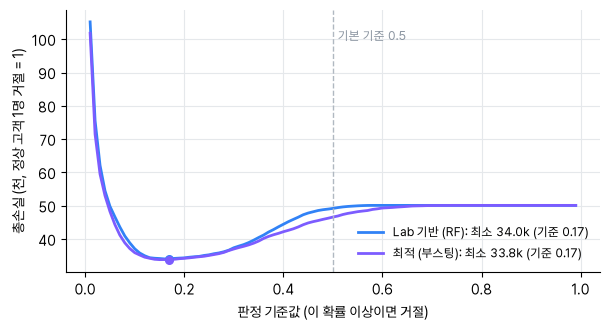

In [5]:
fig, ax = pyplot.subplots(figsize=(6.2, 3.4))
for name, p, col in [('Lab 기반 (RF)', oof_lab, BLUE), ('최적 (부스팅)', oof_opt, VIOLET)]:
    t, c, ts, costs = best_threshold(p, Y, 5)
    ax.plot(ts, numpy.array(costs) / 1000, color=col, lw=2, label=f'{name}: 최소 {c / 1000:.1f}k (기준 {t:.2f})')
    ax.scatter([t], [c / 1000], color=col, s=30, zorder=4)
ax.axvline(0.5, color=GRAY, ls='--', lw=1); ax.text(0.51, ax.get_ylim()[1] * 0.95, '기본 기준 0.5', fontsize=9, color='#8B95A1', va='top')
ax.set_xlabel('판정 기준값 (이 확률 이상이면 거절)'); ax.set_ylabel('총손실 (천, 정상 고객 1명 거절 = 1)')
ax.legend(frameon=False, fontsize=9); ax.spines[['top', 'right']].set_visible(False); ax.grid(color='#E5E8EB'); ax.set_axisbelow(True)
pyplot.tight_layout(); pyplot.savefig('../figures/final_cost_curve.png', dpi=200); pyplot.show()

## 4) 위험 점수 상위 고객에 연체자가 얼마나 몰리나 (처음 보는 고객 기준)

In [6]:
top_rows = []
for top in [0.05, 0.10, 0.20]:
    k = int(len(Y) * top)
    for name, p in [('Lab 기반', oof_lab), ('최적', oof_opt)]:
        caught = Y[numpy.argsort(-p)[:k]].sum(); top_rows.append((f'상위 {top:.0%}', name, caught / Y.sum(), caught / k))
print(DataFrame(top_rows, columns=['구간', '모델', '전체 연체자 중', '그룹 연체율']).to_string(index=False, formatters={'전체 연체자 중': '{:.1%}'.format, '그룹 연체율': '{:.1%}'.format}))

    구간     모델 전체 연체자 중 그룹 연체율
 상위 5% Lab 기반    32.0%  42.7%
 상위 5%     최적    32.3%  43.2%
상위 10% Lab 기반    51.2%  34.2%
상위 10%     최적    51.6%  34.5%
상위 20% Lab 기반    71.1%  23.8%
상위 20%     최적    71.6%  23.9%


## 5) 설명 가능성: 두 모델이 중요하게 본 변수 (순열 중요도: 그 변수를 섞었을 때 AUC가 얼마나 떨어지나)

In [7]:
Xs, _, Ys, _ = train_test_split(X, Y, train_size=(2000 if SMOKE else 20000), random_state=seed, stratify=Y)
imp = {}
for name, m in models.items():
    pi = permutation_importance(m, Xs, Ys, scoring='roc_auc', n_repeats=3, random_state=seed, n_jobs=-1)
    imp[name] = pi.importances_mean
print(DataFrame(imp, index=features).sort_values('Lab 기반: 정리 + RF', ascending=False).round(4).to_string())

           Lab 기반: 정리 + RF  최적: 새 변수 + 튜닝한 부스팅
defaulted           0.0895              0.1059
revol               0.0728              0.0688
debt                0.0198              0.0243
age                 0.0188              0.0119
income              0.0156              0.0215
late30              0.0122              0.0056
depend              0.0049              0.0013
loans               0.0047              0.0007


(순열 중요도는 원래 입력 8개 기준이다. 새 변수는 이 8개에서 계산되므로 원래 변수의 중요도에 함께 들어간다.)

## 6) 한 장 비교

In [8]:
lab_t, opt_t = cost_rows['Lab 기반: 정리 + RF'], cost_rows['최적: 새 변수 + 튜닝한 부스팅']
lab5 = cost_table[(cost_table['비용 비율'] == '5:1') & (cost_table['모델'] == 'Lab 기반')].iloc[0]
opt5 = cost_table[(cost_table['비용 비율'] == '5:1') & (cost_table['모델'] == '최적')].iloc[0]
summary = DataFrame({
    'Lab 기반 (정리 + RF)': [f"{r.Lab.mean():.4f} ± {r.Lab.std(ddof=0):.4f}", f'{lab_t[0]:.1f}초', f'{lab_t[1]:.0f}ms', f'{lab_t[2]:.1f} MB', f"{lab5['손실(최적 기준)']:,} (기준 {lab5['최적 기준값']})", '변수 10개 · 설정 1개 튜닝'],
    '최적 (새 변수 + 부스팅)': [f"{r['최적'].mean():.4f} ± {r['최적'].std(ddof=0):.4f}", f'{opt_t[0]:.1f}초', f'{opt_t[1]:.0f}ms', f'{opt_t[2]:.1f} MB', f"{opt5['손실(최적 기준)']:,} (기준 {opt5['최적 기준값']})", '변수 14개 · 설정 6개 튜닝'],
}, index=['AUC (층화 10-fold)', '15만 건 학습', '1,000명 예측', '파일 크기', '손실 (비용 5:1)', '복잡도'])
print(summary.to_string())

                   Lab 기반 (정리 + RF)    최적 (새 변수 + 부스팅)
AUC (층화 10-fold)    0.8556 ± 0.0070    0.8576 ± 0.0065
15만 건 학습                       5.0초               4.6초
1,000명 예측                      42ms               13ms
파일 크기                        5.5 MB             0.6 MB
손실 (비용 5:1)        34,000 (기준 0.17)   33,830 (기준 0.17)
복잡도               변수 10개 · 설정 1개 튜닝  변수 14개 · 설정 6개 튜닝


## 정리
- **최적 모델이 10조각 모두에서 높았다.** 0.8576 vs 0.8556, 차이 +0.0020 (차이의 흔들림 0.0012). 설정은 바깥 시험 조각을 쓰지 않고 찾았으므로 과장된 값이 아니다.
- 최적 모델은 예측이 3배 빠르고(1,000명 13ms vs 42ms) 파일이 9분의 1(0.6 MB vs 5.5 MB)이다. 대신 변수 14개와 설정 6개를 찾는 데 14분이 들었다.
- **은행 입장의 차이는 작다.** 비용 5:1에서 두 모델 모두 최적 기준값은 0.17이고, 손실 차이는 0.5%(34,000 vs 33,830). 위험 상위 10%가 잡는 연체자도 51.2% vs 51.6%.
- 기준값을 0.5에서 0.17로 낮추면 손실이 31% 줄어든다(연체자 54.5%를 잡고 정상 고객 8%를 거절). 비용 비율이 클수록 기준값이 낮아진다(1:1 0.45, 5:1 0.17, 10:1 0.10).
- 두 모델이 가장 중요하게 본 변수는 같다: 연체 이력, 사용 비율.

**결론:** 문헌 방법을 더한 최적 모델이 근소하게 낫지만, Lab 1~6 과정만으로 만든 모델도 한계에 거의 닿아 있었다. 실무 차이는 판정 기준값을 어떻게 정하느냐가 훨씬 크다.